# Практична робота № 6
## Інтерпретація та перевірка корисності результатів навчання без учителя
**Ковальчук · ІПЗс-24-1 · варіант 5 · Бедратюк Л.П.**

Працюю з фіксованими артефактами ЛР № 5: Breast Cancer Wisconsin, log1p → StandardScaler → PCA(6), K-Means(2).
Новий добір q/K/порогів за мітками не виконується. Мета — перевірити пояснення і обмежені дії, а не дати діагноз.

Виконані перевірки й код підготовлено за допомогою Codex; студентська перевірка та розуміння залишаються необхідними. Фактичні рішення та межі допомоги — в AI_USAGE.md.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/'results').is_dir() else Path.cwd().parent
assert (ROOT/'results/summary.json').is_file()
sys.path.insert(0,str(ROOT))
import audit as A
def table(name): return pd.read_csv(ROOT/'results'/f'{name}.csv')
def picture(name): display(Image(filename=str(ROOT/'figures'/f'{name}.png')))
summary=json.loads((ROOT/'results/summary.json').read_text())
display(pd.Series(summary).to_frame('value'))

,value
train_n,455.000000
test_n,114.000000
q,6.000000
k,2.000000
seed_ari,1.000000
seed_stability_min,1.000000
subsample_ari,0.976923
stability_mean,0.995385
stability_min,0.400000
unstable_n,2.000000


## 1. Постановка, дані, протокол
Профілі рахую в **початкових сирих ознаках**, стандартизую відносно train; відстані — у робочому PCA(6).
Спершу перевірка контракту, профілі, представники і стійкість; потім PCA та scores; далі фіксовані правила;
тільки після цього відкриваю контрольні мітки спотворень для аудиту. Діагноз не є target правил.
Основний запуск: `python pr06_analysis.py`; цей notebook читає збережені результати й перевіряє їх.
Повторні підвибірки генерує RNG(42), кожен K-Means має random_state=42; preprocessing і PCA незмінні.

In [2]:
validation=json.loads((ROOT/'results/validation.json').read_text())
display(validation)
assert validation['valid'] and validation['train_n']==455 and validation['test_n']==114
assert validation['k']==2 and validation['q']==6
display(table('cluster_summary').round(6))

{'valid': True,
 'train_n': 455,
 'test_n': 114,
 'k': 2,
 'input_sha256': {'lr05_bundle.joblib': '811f44e57ca78215e8f6d846ebad5dae6483bafdad48bf9f9dc9242e5f32b7b5',
  'experiment_config.json': '40151751df3e109064c1f752e3522fbabe0e4dd104baf7b5f3c579bf6c801c9d',
  'split_ids.csv': '126b66fb4265d0fe2c7844bf67678fa03bbbe0825881939fdd162647893ed333',
  'selected_k.json': 'e6b029ff7e90f7c2b0a8497762620b0bc142b09a52c719343c44cb2dc35837ca'},
 'q': 6,
 'python': '3.12.0',
 'input_commit': '1bd0b4a',
 'reference_seed': 42}

,cluster,n,fraction,mean_distance,rms_distance,neighbor_cluster,center_distance,mean_stability,unstable_n,boundary_n,jaccard_mean,max_profile_change
0,0,303,0.665934,3.390696,3.664688,1,6.773358,0.993069,2,8,1.0,0.033356
1,1,152,0.334066,4.387414,4.860973,0,6.773358,1.000000,0,3,1.0,0.070265


## 2. Профілі й розміри кластерів
Стандартизований профіль: (середнє кластера − середнє train) / SD(train), ddof=0.
Для сталої ознаки профіль нульовий. Повна long-таблиця зберігає середні, медіани та внутрішній SD.
Показую п'ять найбільших додатних і від'ємних відхилень окремо. Номер кластера не надає йому медичної назви.

,cluster,feature,n,fraction,mean,median,std,profile,direction
0,0,smoothness_se,303,0.6659,0.0071,0.0064,0.0031,0.0034,positive
1,0,concave_points_mean,303,0.6659,0.0255,0.0234,0.0150,-0.5870,negative
2,0,concave_points_worst,303,0.6659,0.0752,0.0743,0.0366,-0.5809,negative
3,0,concavity_mean,303,0.6659,0.0428,0.0361,0.0313,-0.5678,negative
4,0,perimeter_worst,303,0.6659,88.7296,87.5400,15.2408,-0.5397,negative
5,0,concavity_worst,303,0.6659,0.1615,0.1450,0.1115,-0.5335,negative
6,1,concave_points_mean,152,0.3341,0.0938,0.0884,0.0311,1.1702,positive
7,1,concave_points_worst,152,0.3341,0.1912,0.1860,0.0412,1.1580,positive
8,1,concavity_mean,152,0.3341,0.1816,0.1679,0.0720,1.1319,positive
9,1,perimeter_worst,152,0.3341,142.2989,140.2000,30.2851,1.0759,positive


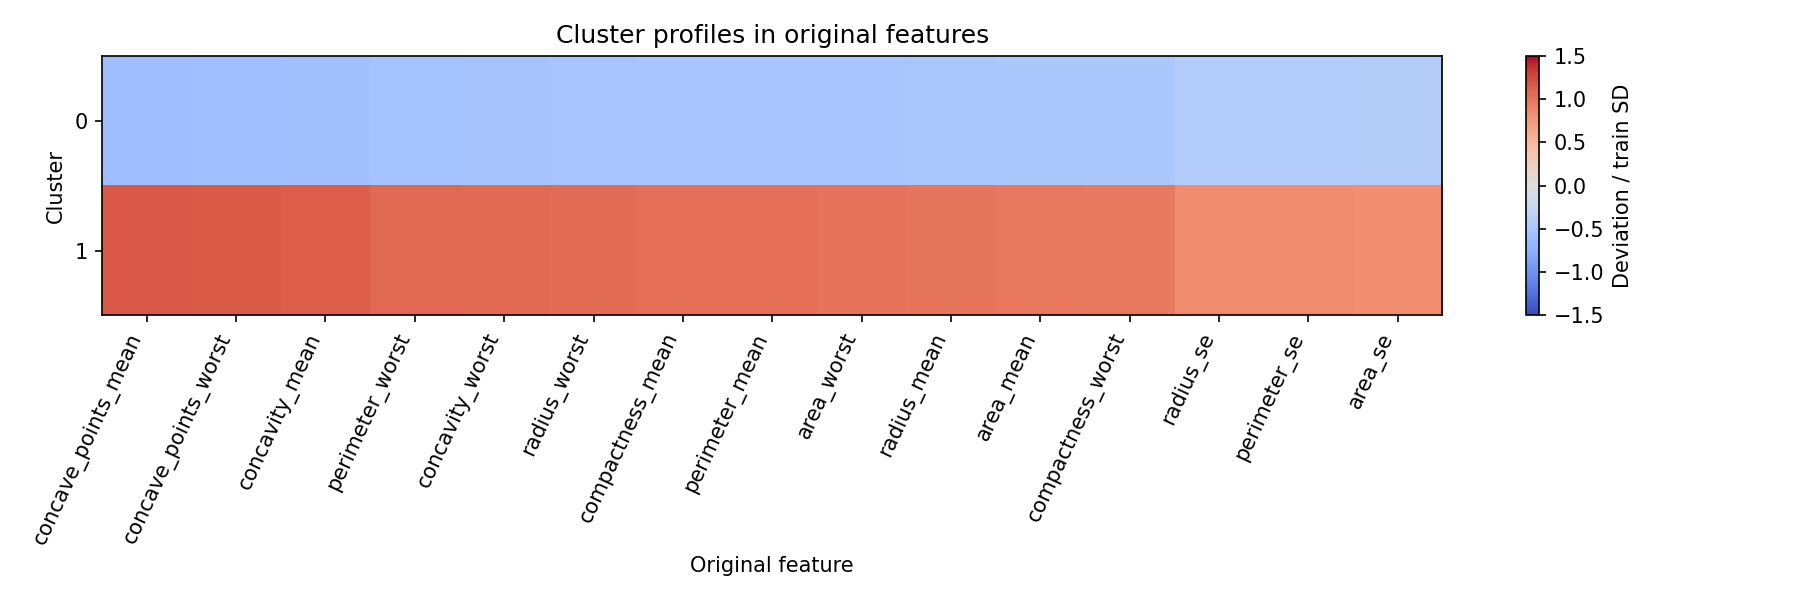

In [3]:
display(table('profile_top_signed').round(4))
picture('01_cluster_profiles')
assert len(table('cluster_profiles'))==60

На heatmap видно протилежні напрямки числових профілів; це опис вимірювань, а не причин або діагнозів.
Середня відстань та RMS у PCA показують ширину групи окремо від її розміру.

## 3. Типові, віддалені й граничні
Типовий — найближчий **реальний запис** до центру; віддалений — найбільша відстань; граничний — малий
(d₂−d₁)/max(d₂, eps). Центроїд може мати значення, яких немає в жодного запису. Граничний не обов'язково віддалений.

,id,kind,cluster,distance,second_distance,margin
0,362,typical,0,0.84844,6.84476,0.87605
1,79,typical,0,0.97020,6.34633,0.84712
2,74,typical,0,1.15953,7.05734,0.83570
3,505,distant,0,9.88355,10.34831,0.04491
4,71,distant,0,9.42381,10.94530,0.13901
5,176,distant,0,9.17071,9.44129,0.02866
6,318,boundary,0,8.10869,8.17352,0.00793
7,86,boundary,0,4.00991,4.04359,0.00833
8,207,boundary,0,4.96329,5.06867,0.02079
9,392,typical,1,1.53882,7.12048,0.78389


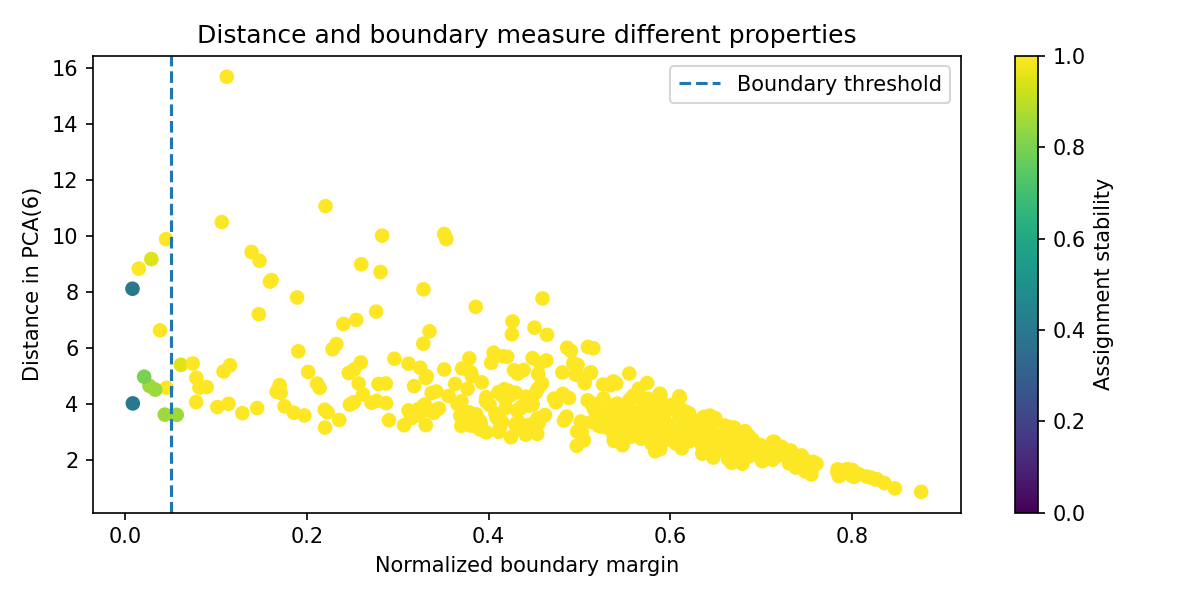

In [4]:
reps=table('representatives')
display(reps.round(5))
assert (reps.groupby(['cluster','kind']).size()==3).all()
picture('02_distance_boundary')

## 4. Стійкість призначень і пояснень
Перевіряю дві різні зміни: п'ять попередніх seeds та 20 підвибірок по 90% train.
Номери кластерів вирівнюю угорським алгоритмом на train, а test прогнозую через те саме вирівнювання.
Контрольна межа S < 0.8; саме значення 0.8 не потрапляє до нестійких. Повторення seed не замінює зміни складу даних.

seed_ari              1.000000
seed_stability_min    1.000000
subsample_ari         0.976923
stability_mean        0.995385
stability_min         0.400000
unstable_n            2.000000
dtype: float64

,id,cluster,distance,second_distance,margin,stability
0,318,0,8.108694,8.173520,0.007931,0.40
1,86,0,4.009911,4.043594,0.008330,0.40
2,207,0,4.963293,5.068673,0.020791,0.80
3,39,0,4.634027,4.760943,0.026658,0.85
4,435,0,4.501797,4.655419,0.032998,0.85
5,99,0,3.608274,3.772620,0.043563,0.85
6,255,0,3.601221,3.817565,0.056670,0.85
7,176,0,9.170715,9.441294,0.028659,0.95
8,469,0,5.389532,5.741301,0.061270,0.95
9,376,1,8.827577,8.960739,0.014861,1.00


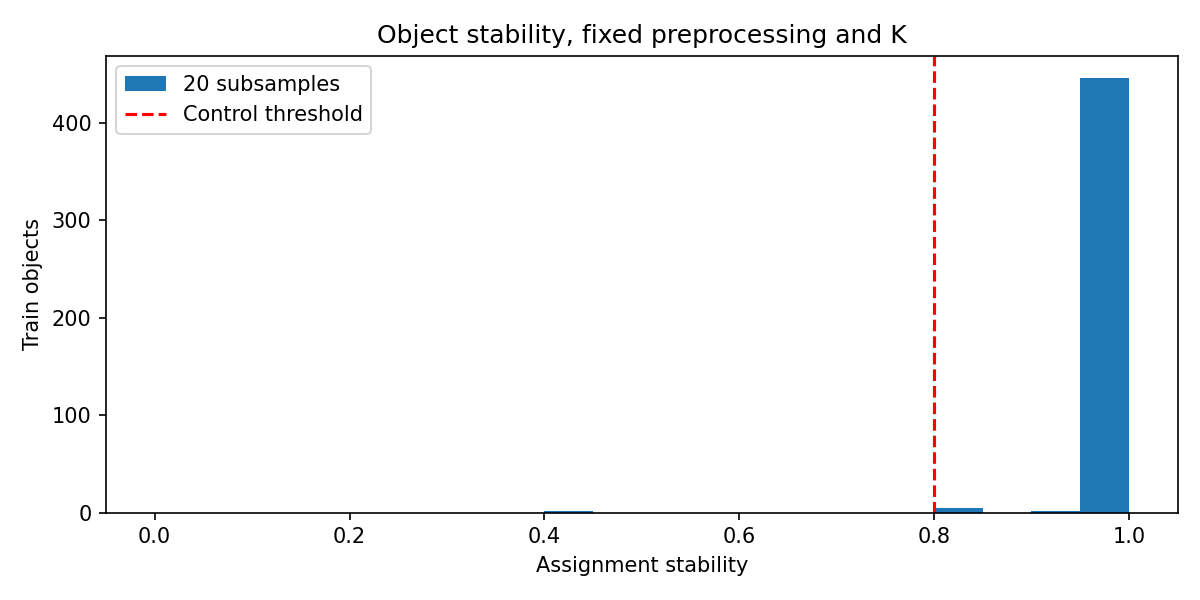

,jaccard_min,jaccard_mean,max_profile_change
cluster,,,
0,1.0,1.0,0.033356
1,1.0,1.0,0.070265


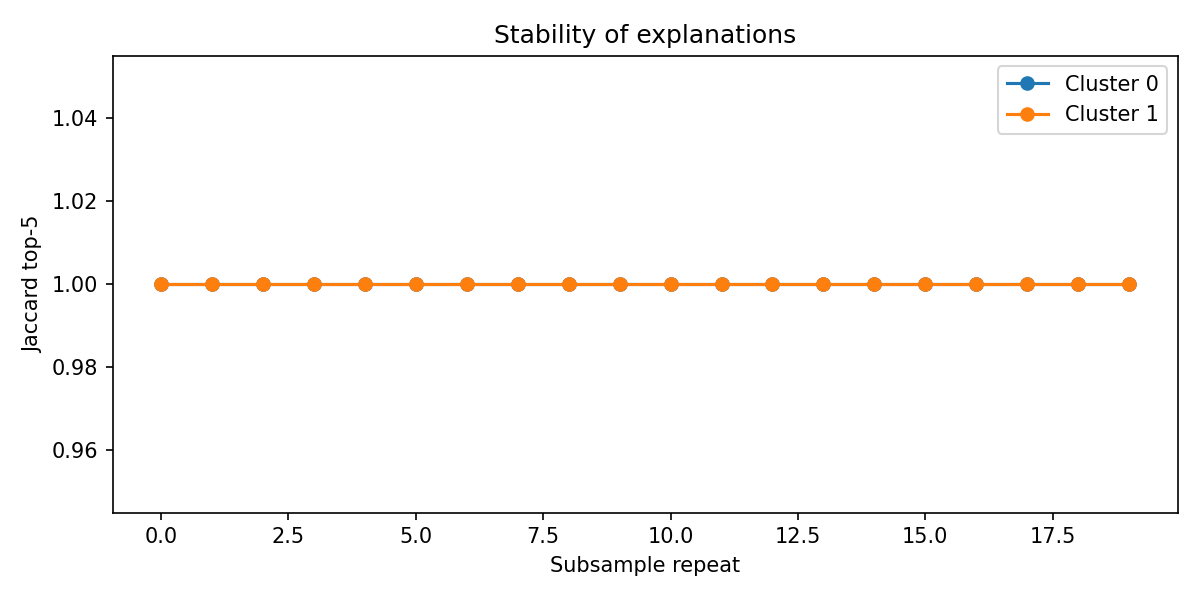

In [5]:
display(pd.Series({k:summary[k] for k in ['seed_ari','seed_stability_min','subsample_ari','stability_mean','stability_min','unstable_n']}))
display(table('least_stable_10').round(6))
picture('03_stability')
ps=table('profile_stability')
display(ps.groupby('cluster').agg(jaccard_min=('jaccard','min'),jaccard_mean=('jaccard','mean'),max_profile_change=('max_abs_profile_change','max')))
picture('04_profile_stability')

П'ять seeds дали стійкість кожного об'єкта 1.0, але підвибірки виявили два об'єкти нижче 0.8.
Top-5 ознак обох кластерів зберігаються (Jaccard=1), хоча числові профілі трохи змінюються.
Тому гіпотезу «стійке розбиття гарантує кожне призначення» відхилено, а гіпотезу про незмінність коротких профілів підтримано.
Таблиця десяти найменш стабільних містить і стабільні записи: нестійких лише два, не треба називати нестійкими всі десять.

## 5. PCA: ваги та крайні об'єкти
Ваги стосуються **стандартизованих log1p-ознак**. PC1 описує спільне збільшення розмірів та нерівності контуру;
PC2 — контраст фрактальних характеристик і розмірів; PC3 — контраст похибок вимірювань і частини worst-характеристик.
Це інтерпретаційні гіпотези, які перевіряю внесками крайніх об'єктів. Знак PCA умовний, причинність не випливає з ваг.

PC 1 positive and negative loadings


,component,feature,weight
7,1,concave_points_mean,0.25899
6,1,concavity_mean,0.25516
27,1,concave_points_worst,0.25121
5,1,compactness_mean,0.24029
26,1,concavity_worst,0.23428


Extreme records with strongest contributions


,component,side,id,coordinate,feature,raw_value,scaled_log_value,contribution
27,1,min,175,-6.33449,concave_points_worst,0.000,-1.79459,-0.45082
22,1,min,175,-6.33449,perimeter_worst,58.360,-1.92565,-0.44747
2,1,min,175,-6.33449,perimeter_mean,54.420,-1.94264,-0.43076
23,1,min,175,-6.33449,area_worst,259.200,-1.89977,-0.42230
20,1,min,175,-6.33449,radius_worst,9.262,-1.85642,-0.41684


,component,side,id,coordinate,feature,raw_value,scaled_log_value,contribution
36,1,max,108,11.93823,concavity_mean,0.4264,3.79575,0.96852
37,1,max,108,11.93823,concave_points_mean,0.1823,3.32630,0.86149
35,1,max,108,11.93823,compactness_mean,0.2768,3.10973,0.74725
56,1,max,108,11.93823,concavity_worst,0.9608,2.77837,0.65093
57,1,max,108,11.93823,concave_points_worst,0.2910,2.52522,0.63436


...

PC 3 positive and negative loadings


,component,feature,weight
71,3,texture_se,0.41950
70,3,radius_se,0.27278
74,3,smoothness_se,0.27229
72,3,perimeter_se,0.26579
78,3,symmetry_se,0.26168
84,3,smoothness_worst,-0.27361
88,3,symmetry_worst,-0.25916
89,3,fractal_dimension_worst,-0.23869
85,3,compactness_worst,-0.22255
86,3,concavity_worst,-0.16465


Extreme records with strongest contributions


,component,side,id,coordinate,feature,raw_value,scaled_log_value,contribution
144,3,min,379,-4.76674,smoothness_worst,0.2184,3.70304,-1.01317
145,3,min,379,-4.76674,compactness_worst,0.9379,3.72114,-0.82815
149,3,min,379,-4.76674,fractal_dimension_worst,0.1403,3.03844,-0.72525
148,3,min,379,-4.76674,symmetry_worst,0.4154,1.92256,-0.49825
146,3,min,379,-4.76674,concavity_worst,0.8402,2.37963,-0.39181


,component,side,id,coordinate,feature,raw_value,scaled_log_value,contribution
164,3,max,213,6.78877,smoothness_se,0.03113,7.61727,2.07414
167,3,max,213,6.78877,concave_points_se,0.03927,4.35731,0.89013
169,3,max,213,6.78877,fractal_dimension_se,0.01256,3.16061,0.59642
178,3,max,213,6.78877,symmetry_worst,0.16030,-2.17260,0.56305
166,3,max,213,6.78877,concavity_se,0.14380,3.50946,0.52569


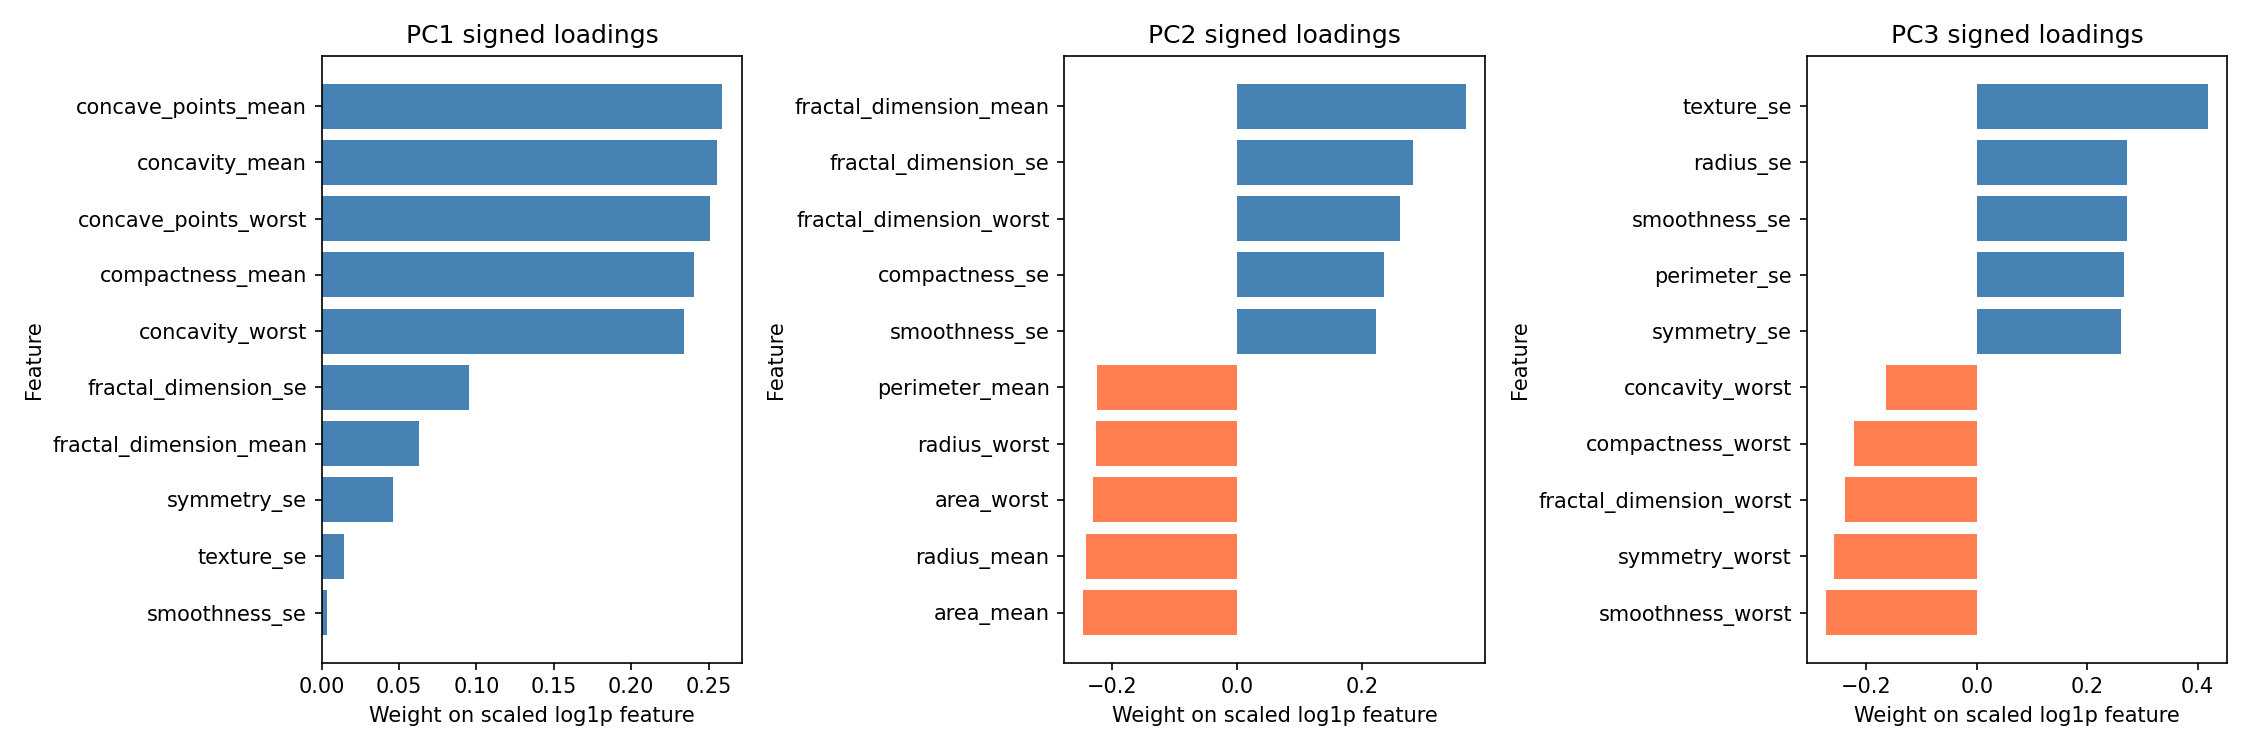

In [6]:
loads=table('pca_loadings');ext=table('pca_extrema')
for pc in [1,2,3]:
    g=loads[loads.component.eq(pc)]
    print('PC',pc,'positive and negative loadings')
    display(pd.concat([g[g.weight>0].nlargest(5,'weight'),g[g.weight<0].nsmallest(5,'weight')]).round(5))
    print('Extreme records with strongest contributions')
    for side in ['min','max']:
        e=ext[ext.component.eq(pc)&ext.side.eq(side)]
        display(e.assign(abs_contribution=e.contribution.abs()).nlargest(5,'abs_contribution').drop(columns='abs_contribution').round(5))
picture('05_pca_signed_loadings')

Великої ваги недостатньо: об'єкт може мати мале значення відповідної ознаки, тому його внесок буде малим.
Перевірка всіх внесків, а не лише top-5, наведена в CSV. Контрприклад предметному діагнозу: низька PCA-координата
не виключає злоякісності, бо компонента оптимізує дисперсію без діагнозу. Двовимірної проєкції для висновку недостатньо.

## 6. Scores, правила та картки
IF-PCA оцінює нетиповість усередині підпростору, reconstruction — відхилення поза ним.
Процентиль — частка train scores ≤ поточного; це не ймовірність спотворення.
Пріоритети та пороги читаються з JSON, усі одночасні умови журналюються.

{'seed': 42,
 'repeats': 20,
 'subsample_fraction': 0.9,
 'stability_threshold': 0.8,
 'boundary_threshold': 0.05,
 'policy': [{'action': 'manual_review',
   'column': 'pct_combined',
   'operator': 'ge',
   'threshold': 0.99},
  {'action': 'data_quality_check',
   'column': 'pct_rec',
   'operator': 'ge',
   'threshold': 0.95},
  {'action': 'uncertain_segment',
   'column': 'stability',
   'operator': 'lt',
   'threshold': 0.8}],
 'scenarios': {'quality_triage': {'max_review_fraction': 0.3,
   'latency_budget_ms': 1000,
   'fp_cost_minutes': 3,
   'fn_cost_units': 20},
  'automatic_rejection': {'max_review_fraction': 0.1,
   'latency_budget_ms': 100,
   'fp_cost_units': 100,
   'fn_cost_units': 20}}}

{'old_commit': '8aaf097',
 'old_disagreement_ids': [298, 434, 428, 452, 495],
 'old_true_disagreements': 1,
 'old_incorrect_cards': 4,
 'fixed_disagreement_ids': [298, 359, 501, 519, 417],
 'fixed_true_disagreements': 5}

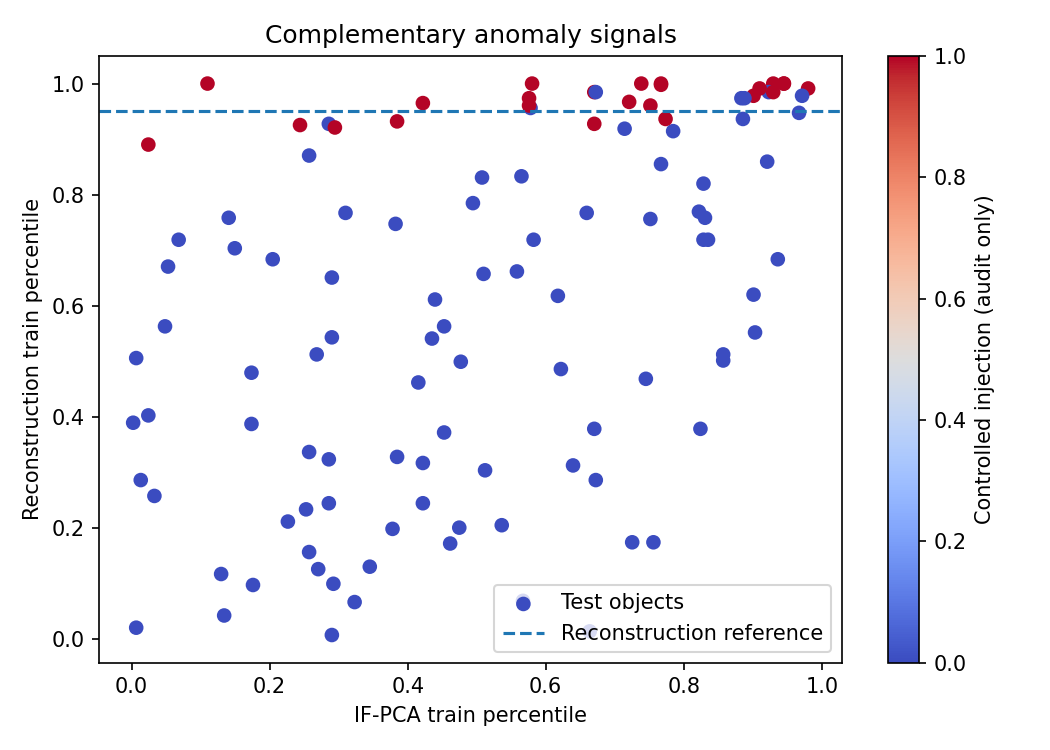

,id,cluster,stability,margin,score_if30,score_ifpca,score_rec,score_combined,pct_if30,pct_ifpca,pct_rec,pct_combined,action,triggered_rules,largest_residual_feature,largest_residual,category,hypothesis,recommended_action,limitation
0,247,1,1.00,0.242220,0.576583,0.547559,5.055814,1.000000,0.980220,0.945055,1.000000,1.000000,manual_review,manual_review|data_quality_check,compactness_mean,33.678245,top_combined,Перевірити вимірювання compactness_mean; найбі...,manual_review,Нетиповість не встановлює причину і не є діагн...
1,564,1,1.00,0.498333,0.571048,0.522367,3.888413,1.000000,0.973626,0.929670,1.000000,1.000000,manual_review,manual_review|data_quality_check,symmetry_mean,67.422814,top_combined,Перевірити вимірювання symmetry_mean; найбільш...,manual_review,Нетиповість не встановлює причину і не є діагн...
2,95,1,1.00,0.686825,0.506117,0.429967,2.450781,1.000000,0.903297,0.580220,1.000000,1.000000,manual_review,manual_review|data_quality_check,fractal_dimension_mean,48.833382,top_combined,Перевірити вимірювання fractal_dimension_mean;...,manual_review,Нетиповість не встановлює причину і не є діагн...
3,408,1,1.00,0.613786,0.562566,0.456603,2.427967,1.000000,0.962637,0.767033,1.000000,1.000000,manual_review,manual_review|data_quality_check,compactness_mean,11.181561,top_combined,Перевірити вимірювання compactness_mean; найбі...,manual_review,Нетиповість не встановлює причину і не є діагн...
4,537,1,1.00,0.063327,0.537494,0.546287,2.216446,1.000000,0.936264,0.945055,1.000000,1.000000,manual_review,manual_review|data_quality_check,smoothness_worst,10.039345,top_combined,Перевірити вимірювання smoothness_worst; найбі...,manual_review,Нетиповість не встановлює причину і не є діагн...
5,298,0,1.00,0.619533,0.532725,0.388420,1.596360,1.000000,0.934066,0.109890,1.000000,1.000000,manual_review,manual_review|data_quality_check,symmetry_mean,8.878508,detector_disagreement,Перевірити вимірювання symmetry_mean; найбільш...,manual_review,Нетиповість не встановлює причину і не є діагн...
6,359,0,1.00,0.337649,0.438205,0.413875,0.321852,0.964835,0.663736,0.421978,0.964835,0.953846,data_quality_check,data_quality_check,fractal_dimension_mean,2.642310,detector_disagreement,Перевірити вимірювання fractal_dimension_mean;...,data_quality_check,Нетиповість не встановлює причину і не є діагн...
7,501,1,1.00,0.694497,0.503434,0.429237,0.341302,0.973626,0.901099,0.575824,0.973626,0.969231,data_quality_check,data_quality_check,concave_points_mean,1.481540,detector_disagreement,Перевірити вимірювання concave_points_mean; на...,data_quality_check,Нетиповість не встановлює причину і не є діагн...
8,519,1,1.00,0.310387,0.443851,0.429580,0.299354,0.960440,0.703297,0.575824,0.960440,0.947253,data_quality_check,data_quality_check,concave_points_mean,1.814622,detector_disagreement,Перевірити вимірювання concave_points_mean; на...,data_quality_check,Нетиповість не встановлює причину і не є діагн...
9,417,1,1.00,0.691665,0.479715,0.429933,0.285242,0.956044,0.843956,0.578022,0.956044,0.942857,data_quality_check,data_quality_check,radius_se,1.997787,detector_disagreement,Перевірити вимірювання radius_se; найбільший к...,data_quality_check,Нетиповість не встановлює причину і не є діагн...


In [7]:
display(json.loads((ROOT/'configs/audit.json').read_text()))
display(json.loads((ROOT/'results/repair_evidence.json').read_text()))
picture('06_anomaly_signals')
cards=table('anomaly_cards')
display(cards)
assert len(cards)==15 and cards.id.nunique()==15
scores=table('scores_actions')
rules=json.loads((ROOT/'configs/audit.json').read_text())['policy']
check=A.apply_action_policy(scores,rules)
assert check.action.tolist()==scores.action.tolist()
assert not any('label' in rule['column'] or 'diagnos' in rule['column'] for rule in rules)

Картки: п'ять top combined, п'ять розбіжностей IF-PCA/reconstruction та п'ять false positives;
усі 15 ID різні. Гіпотеза перевірки називає найбільший залишок ознаки, але не стверджує причину.

## 7. Наслідки та практична корисність
Контрольні спотворення відкриваються **після** обчислення action. FP тут означає «не ін'єктовано», а не «клінічно здоровий».
Фіксована політика направляє до оператора 24 об'єкти: 18 TP, 6 FP; пропущено 6 FN. Precision=recall=0.75.
Вісім конфліктів вирішено заданим порядком. Сценарні ціни — навчальні припущення, не виміряні економічні втрати.

,action,n,tp,conflicts,fp,fraction
0,data_quality_check,16,10,0,6,0.14035
1,manual_review,8,8,8,0,0.07018
2,no_action,90,6,0,84,0.78947


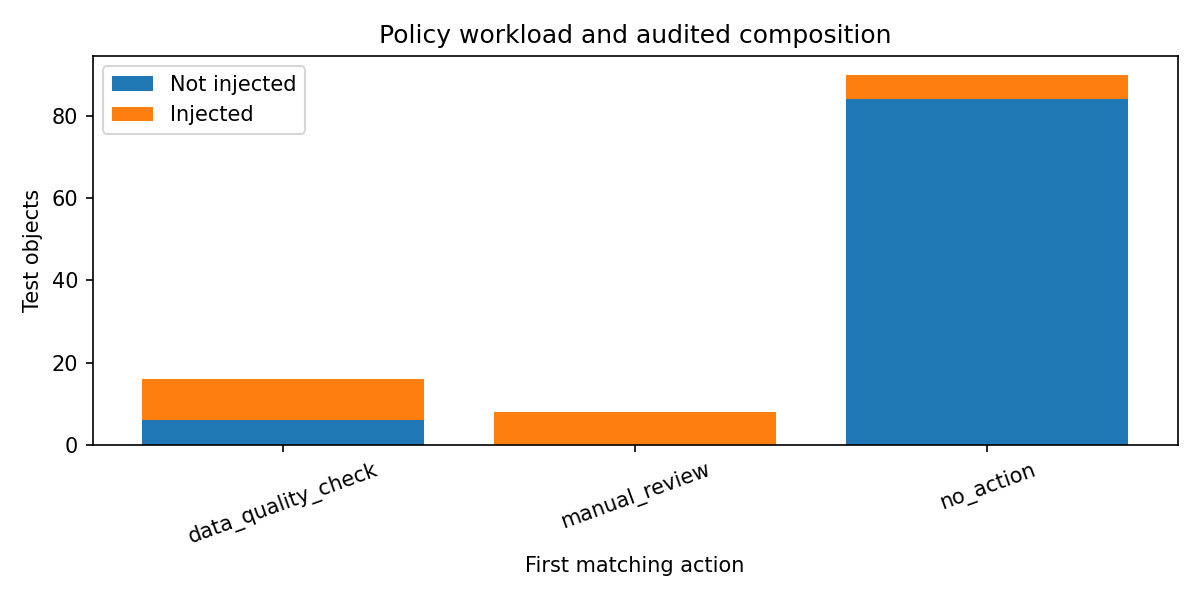

,scenario,user,max_review_fraction,allowed_latency_ms,fp_cost,fn_cost,decision
0,Quality triage,Оператор якості вимірювань,0.3,1000,3,20,"Обмежено: ручна перевірка, не відбракування"
1,Automatic rejection,Автоматичний імпортер записів,0.1,100,100,20,Відхилено: FP і FN несумісні з автоматичною дією


In [8]:
display(table('action_summary').round(5))
picture('07_actions')
display(pd.DataFrame([
 {'scenario':'Quality triage','user':'Оператор якості вимірювань','max_review_fraction':.30,'allowed_latency_ms':1000,'fp_cost':3,'fn_cost':20,'decision':'Обмежено: ручна перевірка, не відбракування'},
 {'scenario':'Automatic rejection','user':'Автоматичний імпортер записів','max_review_fraction':.10,'allowed_latency_ms':100,'fp_cost':100,'fn_cost':20,'decision':'Відхилено: FP і FN несумісні з автоматичною дією'}
]))
assert summary['review_n']==summary['tp']+summary['fp']
assert summary['test_n']==sum(summary[k] for k in ['tp','fp','fn','tn'])

## 8. Висновки й межі
Результат придатний як **офлайнова допомога оператору**: за припущення 3 хвилини на запис це 72 хвилини роботи.
Автоматично можна обчислювати scores, пояснення й маршрут; виключення запису або медичне рішення потребує людини.
Операційна затримка всього контуру не вимірювалась: задані 1000/100 мс залишаються вимогами майбутнього прототипу.
Зупинка: порушення схеми/діапазонів, зміна розподілу, перевищення бюджету перевірок; пороги переглядати на новій валідації.
Обидва top-5 профілі стійкі, але ID 318 та 86 мають S=0.4. Предметні назви кластерів і причина реальної аномалії залишаються відкритими.
Тести: `python -m unittest discover -s tests -v`. Вхідний bundle відтворюється командою `python ../lab05/lr05_experiment.py` з кореня ПР.